In [ ]:
!pip install keras-tuner --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 5.1 MB/s eta 0:00:00


## Supervised Classification

### 1. Load data

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
DATASET_DIR = "/content/drive/Shareddrives/CV_Project/Supervised_Classification/data/IndustryBiscuit/DS_multiclass"

Mounted at /content/drive


In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import os

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.19.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
IMG_SIZE = (256, 256)
BATCH_SIZE = 32

train_ds_raw = tf.keras.preprocessing.image_dataset_from_directory(
    os.path.join(DATASET_DIR, "train"),
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

valid_ds_raw = tf.keras.preprocessing.image_dataset_from_directory(
    os.path.join(DATASET_DIR, "valid"),
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

test_ds_raw = tf.keras.preprocessing.image_dataset_from_directory(
    os.path.join(DATASET_DIR, "test"),
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)


Found 3918 files belonging to 4 classes.
Found 490 files belonging to 4 classes.
Found 492 files belonging to 4 classes.


In [ ]:
class_names = train_ds_raw.class_names
class_names

['Defect_Color', 'Defect_No', 'Defect_Object', 'Defect_Shape']

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds_raw.prefetch(AUTOTUNE)
valid_ds = valid_ds_raw.prefetch(AUTOTUNE)
test_ds = test_ds_raw.prefetch(AUTOTUNE)

In [ ]:
import matplotlib.pyplot as plt

def plot_training_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']

    epochs = range(1, len(acc)+1)

    plt.figure(figsize=(12,5))

    # Accuracy
    plt.subplot(1,2,1)
    plt.plot(epochs, acc, 'b-', label="Training Acc")
    plt.plot(epochs, val_acc, 'r-', label="Validation Acc")
    plt.title("Accuracy Over Epochs")
    plt.legend()

    # Loss
    plt.subplot(1,2,2)
    plt.plot(epochs, loss, 'b-', label="Training Loss")
    plt.plot(epochs, val_loss, 'r-', label="Validation Loss")
    plt.title("Loss Over Epochs")
    plt.legend()

    plt.show()


In [ ]:
import numpy as np
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix, classification_report,
    roc_curve, auc, precision_recall_curve
)
import matplotlib.pyplot as plt

def evaluate_model(model, test_ds, class_names):
    # -----------------------------
    # 1. Collect all predictions
    # -----------------------------
    y_true = []
    y_pred = []

    for img, label in test_ds:
        preds = model.predict(img)
        y_true.extend(np.argmax(label.numpy(), axis=1))
        y_pred.extend(np.argmax(preds, axis=1))

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    # -----------------------------
    # 2. Confusion Matrix
    # -----------------------------
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt="d",
                xticklabels=class_names,
                yticklabels=class_names,
                cmap="Blues")
    plt.title("Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

    # -----------------------------
    # 3. Classification Report
    # -----------------------------
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=class_names))


### 3. Transfer Learning Models

3.1 ResNet50V2

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers

IMG_SIZE = (256, 256)
NUM_CLASSES = 4

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
])


In [1]:
from tensorflow.keras.applications import ResNet50V2
base_model = ResNet50V2(
    weights="imagenet",
    include_top=False,
    input_shape=(256, 256, 3)
)


94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [2]:
base_model.summary()

Model: "resnet50v2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 262, 262,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 128, 128,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 130, 130,  │          0 │ conv1_conv[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 64, 64,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_preac… │ (None, 64, 64,    │        256 │ pool1_pool[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_preac… │ (None, 64, 64,    │          0 │ conv2_block1_pre… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 64, 64,    │      4,096 │ conv2_block1_pre… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 64, 64,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 64, 64,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_pad  │ (None, 66, 66,    │          0 │ conv2_block1_1_r… │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 64, 64,    │     36,864 │ conv2_block1_2_p… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 64, 64,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 64, 64,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 64, 64,    │     16,640 │ conv2_block1_pre… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 64, 64,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_out    │ (None, 64, 64,    │          0 │ conv2_block1_0_c

 Total params: 23,564,800 (89.89 MB)

 Trainable params: 23,519,360 (89.72 MB)

 Non-trainable params: 45,440 (177.50 KB)

In [ ]:
# Only train classification head
from tensorflow.keras.applications import ResNet50V2

def build_resnet_transfer():
    base_model = ResNet50V2(
        weights="imagenet",
        include_top=False,
        input_shape=(256, 256, 3)
    )
    base_model.trainable = False   # froze backbone

    inputs = layers.Input(shape=(256, 256, 3))
    x = data_augmentation(inputs)
    x = layers.Rescaling(1./255)(x)

    x = base_model(x, training=False)        # set training=False
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)

    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    model = models.Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
        loss="categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

resnet_model = build_resnet_transfer()

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_resnet = resnet_model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=15,
    callbacks=[early_stop]
)

94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/15
123/123 ━━━━━━━━━━━━━━━━━━━━ 580s 5s/step - accuracy: 0.3981 - loss: 1.4975 - val_accuracy: 0.6612 - val_loss: 0.9124
Epoch 2/15
123/123 ━━━━━━━━━━━━━━━━━━━━ 19s 156ms/step - accuracy: 0.5618 - loss: 1.0601 - val_accuracy: 0.7367 - val_loss: 0.7113
Epoch 3/15
123/123 ━━━━━━━━━━━━━━━━━━━━ 20s 160ms/step - accuracy: 0.6606 - loss: 0.8672 - val_accuracy: 0.7959 - val_loss: 0.5909
Epoch 4/15
123/123 ━━━━━━━━━━━━━━━━━━━━ 20s 156ms/step - accuracy: 0.7136 - loss: 0.7405 - val_accuracy: 0.8184 - val_loss: 0.5236
Epoch 5/15
123/123 ━━━━━━━━━━━━━━━━━━━━ 19s 158ms/step - accuracy: 0.7751 - loss: 0.6148 - val_accuracy: 0.8510 - val_loss: 0.4695
Epoch 6/15
123/123 ━━━━━━━━━━━━━━━━━━━━ 19s 156ms/step - accuracy: 0.7832 - loss: 0.5727 - val_accuracy: 0.8714 - val_loss: 0.4252
Epoch 7/15
123/123 ━━━━━━━━━━━━━━━━━━━━ 20s 161ms/step - accuracy: 0.8120 - loss: 0.5356 - val_accuracy: 0.8735 - val_loss: 0.4001
Epoch 8/15
123/123 ━━━━━━━━━━━━━━━

In [ ]:
resnet_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50v2 (Functional)         │ (None, 8, 8, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 52,460,038 (200.12 MB)

 Trainable params: 14,443,520 (55.10 MB)

 Non-trainable params: 9,129,476 (34.83 MB)

 Optimizer params: 28,887,042 (110.20 MB)

In [ ]:
resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history_resnet2 = resnet_model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=30,
    callbacks=[early_stop]
)

Epoch 1/30
123/123 ━━━━━━━━━━━━━━━━━━━━ 28s 177ms/step - accuracy: 0.8874 - loss: 0.3486 - val_accuracy: 0.9041 - val_loss: 0.2778
Epoch 2/30
123/123 ━━━━━━━━━━━━━━━━━━━━ 20s 158ms/step - accuracy: 0.8877 - loss: 0.3296 - val_accuracy: 0.9041 - val_loss: 0.2765
Epoch 3/30
123/123 ━━━━━━━━━━━━━━━━━━━━ 20s 161ms/step - accuracy: 0.8820 - loss: 0.3418 - val_accuracy: 0.9041 - val_loss: 0.2753
Epoch 4/30
123/123 ━━━━━━━━━━━━━━━━━━━━ 19s 154ms/step - accuracy: 0.8904 - loss: 0.3299 - val_accuracy: 0.9041 - val_loss: 0.2744
Epoch 5/30
123/123 ━━━━━━━━━━━━━━━━━━━━ 19s 158ms/step - accuracy: 0.8913 - loss: 0.3314 - val_accuracy: 0.9061 - val_loss: 0.2722
Epoch 6/30
123/123 ━━━━━━━━━━━━━━━━━━━━ 19s 155ms/step - accuracy: 0.8876 - loss: 0.3323 - val_accuracy: 0.9041 - val_loss: 0.2718
Epoch 7/30
123/123 ━━━━━━━━━━━━━━━━━━━━ 20s 159ms/step - accuracy: 0.8952 - loss: 0.3219 - val_accuracy: 0.9082 - val_loss: 0.2706
Epoch 8/30
123/123 ━━━━━━━━━━━━━━━━━━━━ 19s 155ms/step - accuracy: 0.8973 - loss: 0

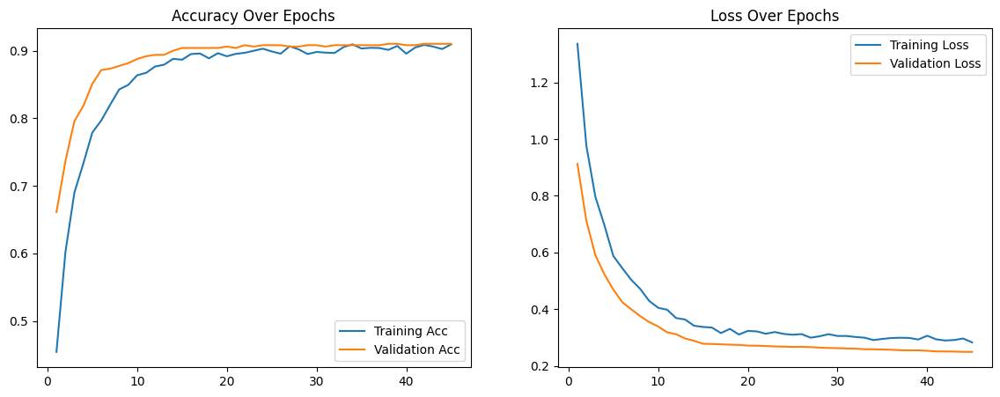

In [ ]:
history1 = history_resnet
history2 = history_resnet2

total_acc = history1.history['accuracy'] + history2.history['accuracy']
total_val_acc = history1.history['val_accuracy'] + history2.history['val_accuracy']

total_loss = history1.history['loss'] + history2.history['loss']
total_val_loss = history1.history['val_loss'] + history2.history['val_loss']

epochs_range = range(1, len(total_acc) + 1)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, total_acc, label="Training Acc")
plt.plot(epochs_range, total_val_acc, label="Validation Acc")
plt.legend()
plt.title("Accuracy Over Epochs")

plt.subplot(1, 2, 2)
plt.plot(epochs_range, total_loss, label="Training Loss")
plt.plot(epochs_range, total_val_loss, label="Validation Loss")
plt.legend()
plt.title("Loss Over Epochs")

plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 334ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 224ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 221ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 174ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 169ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step


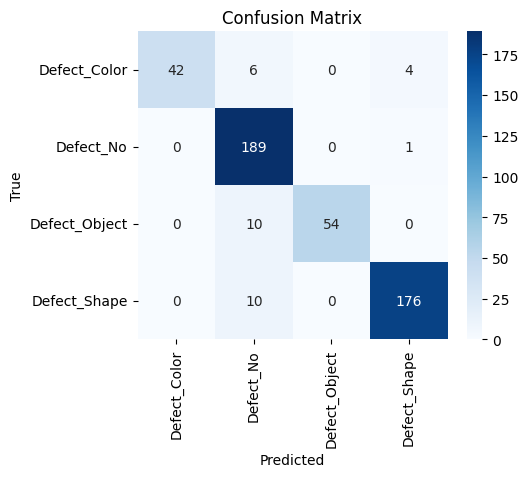


Classification Report:
               precision    recall  f1-score   support

 Defect_Color       1.00      0.81      0.89        52
    Defect_No       0.88      0.99      0.93       190
Defect_Object       1.00      0.84      0.92        64
 Defect_Shape       0.97      0.95      0.96       186

     accuracy                           0.94       492
    macro avg       0.96      0.90      0.93       492
 weighted avg       0.94      0.94      0.94       492



In [ ]:
evaluate_model(resnet_model, test_ds, class_names)


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.utils import load_img, img_to_array

IMG_SIZE = (256, 256)

def find_misclassified_from_dir(model, test_root, class_names, max_show=10):
    """
    test_root:  ".../IndustryBiscuit/DS_multiclass/test"
    class_names: ['Defect_Color', 'Defect_No', 'Defect_Object', 'Defect_Shape']

    """
    misclassified = []

    for cls_name in class_names:
        cls_dir = os.path.join(test_root, cls_name)
        for fname in os.listdir(cls_dir):
            if not fname.lower().endswith((".jpg", ".jpeg", ".png")):
                continue

            fpath = os.path.join(cls_dir, fname)

            img = load_img(fpath, target_size=IMG_SIZE)
            x = img_to_array(img)
            x = np.expand_dims(x, axis=0)   # (1, H, W, 3)

            preds = model.predict(x, verbose=0)
            pred_idx = np.argmax(preds[0])
            pred_class = class_names[pred_idx]

            if pred_class != cls_name:
                misclassified.append({
                    "file": fpath,
                    "true": cls_name,
                    "pred": pred_class,
                    "img": img
                })

    print(f"Total misclassified images: {len(misclassified)}")

    for m in misclassified[:max_show]:
        plt.figure(figsize=(4, 4))
        plt.imshow(m["img"])
        plt.title(f"True: {m['true']} | Pred: {m['pred']}\n{os.path.basename(m['file'])}")
        plt.axis("off")
        plt.show()

    return misclassified


In [ ]:
import os

root = os.path.join(DATASET_DIR, "test")
for cls in os.listdir(root):
    print(cls, "→", len(os.listdir(os.path.join(root, cls))))

Defect_No → 190
Defect_Shape → 186
Defect_Object → 64
Defect_Color → 52


Total misclassified images: 31


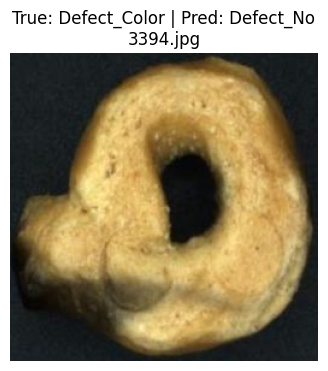

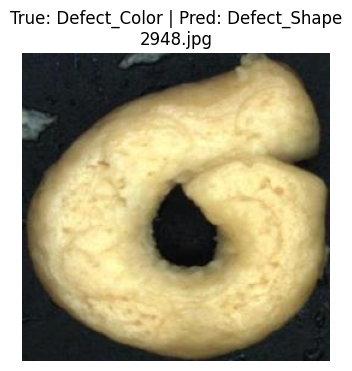

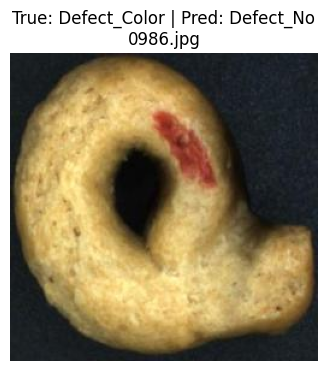

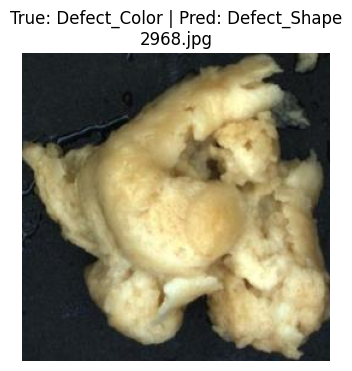

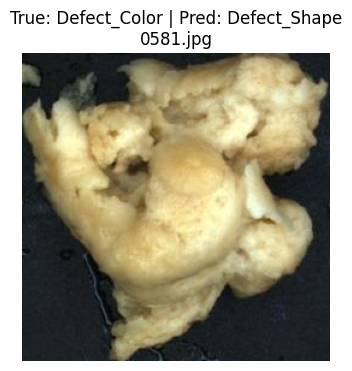

...

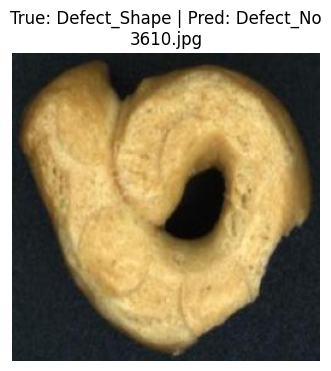

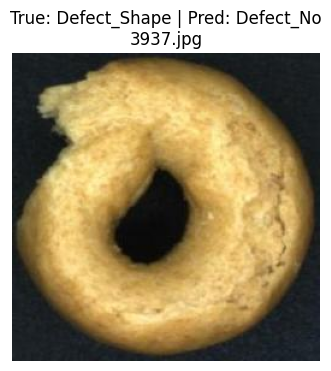

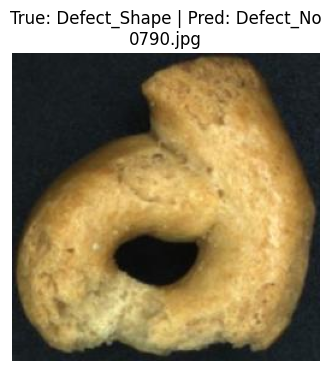

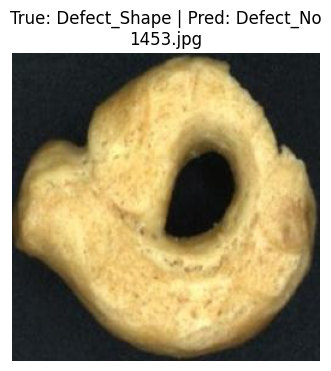

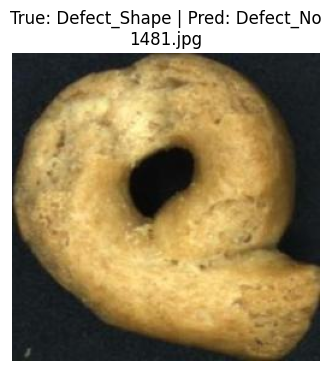

In [ ]:
test_root = os.path.join(DATASET_DIR, "test")
mis = find_misclassified_from_dir(resnet_model, test_root, class_names, max_show=50)



In [ ]:
base_model = resnet_model.layers[3]
print(len(resnet_model.layers))
print(len(base_model.layers))

7
190


In [ ]:
backbone = resnet_model.layers[3]

backbone.trainable = True
for layer in backbone.layers[:-30]:
    layer.trainable = False

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history_ft = resnet_model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=10,
    callbacks=[early_stop]
)


Epoch 1/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 43s 257ms/step - accuracy: 0.5004 - loss: 2.0061 - val_accuracy: 0.8388 - val_loss: 0.3931
Epoch 2/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 28s 227ms/step - accuracy: 0.9431 - loss: 0.2502 - val_accuracy: 0.9286 - val_loss: 0.1722
Epoch 3/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 27s 222ms/step - accuracy: 0.9617 - loss: 0.1569 - val_accuracy: 0.9694 - val_loss: 0.0925
Epoch 4/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 26s 211ms/step - accuracy: 0.9752 - loss: 0.1032 - val_accuracy: 0.9857 - val_loss: 0.0654
Epoch 5/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 27s 216ms/step - accuracy: 0.9831 - loss: 0.0746 - val_accuracy: 0.9898 - val_loss: 0.0508
Epoch 6/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 27s 215ms/step - accuracy: 0.9854 - loss: 0.0559 - val_accuracy: 0.9898 - val_loss: 0.0433
Epoch 7/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 26s 212ms/step - accuracy: 0.9905 - loss: 0.0418 - val_accuracy: 0.9918 - val_loss: 0.0358
Epoch 8/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 26s 213ms/step - accuracy: 0.9899 - loss: 0

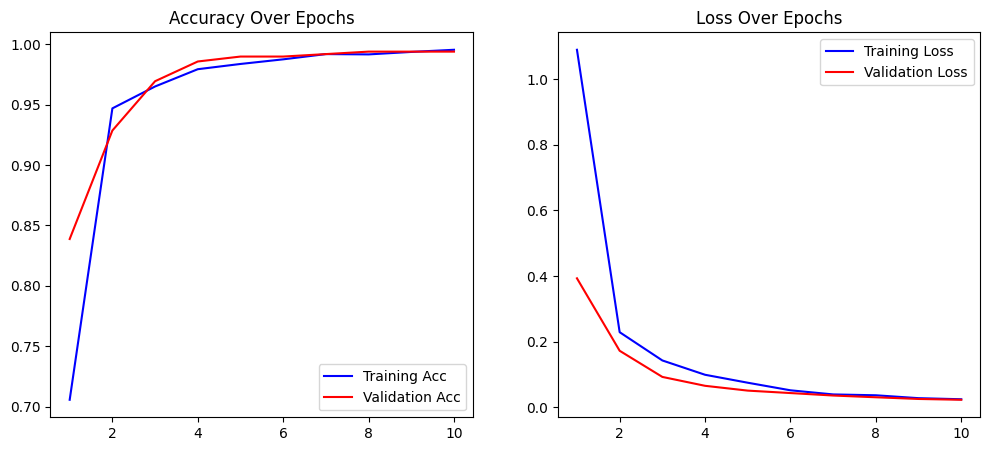

In [ ]:
plot_training_history(history_ft)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 208ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 186ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 188ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 199ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 200ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 174ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


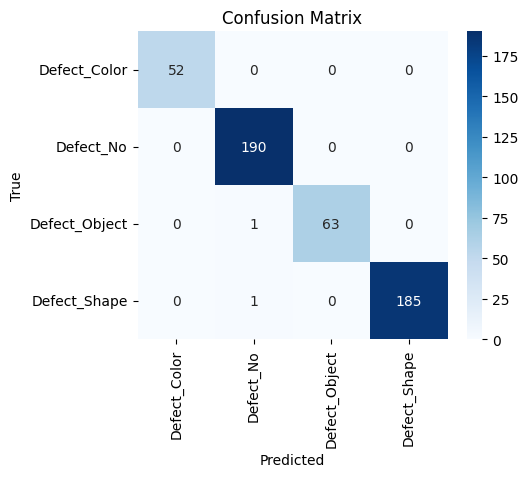


Classification Report:
               precision    recall  f1-score   support

 Defect_Color       1.00      1.00      1.00        52
    Defect_No       0.99      1.00      0.99       190
Defect_Object       1.00      0.98      0.99        64
 Defect_Shape       1.00      0.99      1.00       186

     accuracy                           1.00       492
    macro avg       1.00      0.99      1.00       492
 weighted avg       1.00      1.00      1.00       492



In [ ]:
evaluate_model(resnet_model, test_ds, class_names)

Total misclassified images: 2


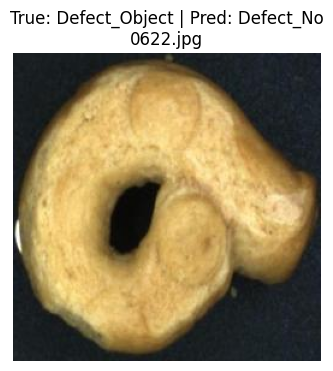

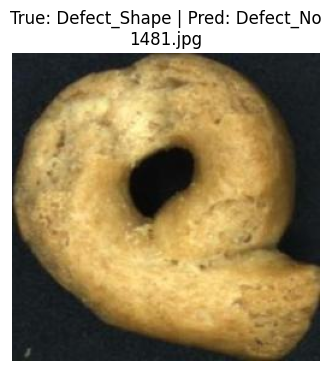

[{'file': '/content/drive/Shareddrives/CV_Project/Supervised_Classification/data/IndustryBiscuit/DS_multiclass/test/Defect_Object/0622.jpg',
  'true': 'Defect_Object',
  'pred': 'Defect_No',
  'img': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=256x256>},
 {'file': '/content/drive/Shareddrives/CV_Project/Supervised_Classification/data/IndustryBiscuit/DS_multiclass/test/Defect_Shape/1481.jpg',
  'true': 'Defect_Shape',
  'pred': 'Defect_No',
  'img': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=256x256>}]

In [ ]:
find_misclassified_from_dir(resnet_model, test_root, class_names, max_show=50)

#### Efficient Net

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetV2B0
from tensorflow.keras.applications.efficientnet_v2 import preprocess_input

NUM_CLASSES = 4
IMG_SIZE = (256, 256)

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
])


def build_efficientnet_transfer():
    base_model = EfficientNetV2B0(
        include_top=False,
        weights="imagenet",
        input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)
    )
    base_model.trainable = False  # freeze backbone

    inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
    x = data_augmentation(inputs)

    x = preprocess_input(x)

    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)

    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    model = models.Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

effnet_model = build_efficientnet_transfer()
effnet_model.summary()



Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_2 (Sequential)       │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-b0 (Functional)  │ (None, 8, 8, 1280)     │     5,919,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,924,436 (22.60 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 5,919,312 (22.58 MB)

In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_effnet = effnet_model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=40,
    callbacks=[early_stop]
)


Epoch 1/40
123/123 ━━━━━━━━━━━━━━━━━━━━ 31s 156ms/step - accuracy: 0.4066 - loss: 1.3569 - val_accuracy: 0.6102 - val_loss: 1.0140
Epoch 2/40
123/123 ━━━━━━━━━━━━━━━━━━━━ 17s 138ms/step - accuracy: 0.5877 - loss: 1.0275 - val_accuracy: 0.6633 - val_loss: 0.8709
Epoch 3/40
123/123 ━━━━━━━━━━━━━━━━━━━━ 17s 140ms/step - accuracy: 0.6382 - loss: 0.9053 - val_accuracy: 0.6980 - val_loss: 0.7708
Epoch 4/40
123/123 ━━━━━━━━━━━━━━━━━━━━ 22s 149ms/step - accuracy: 0.7027 - loss: 0.7991 - val_accuracy: 0.7245 - val_loss: 0.6999
Epoch 5/40
123/123 ━━━━━━━━━━━━━━━━━━━━ 17s 135ms/step - accuracy: 0.7439 - loss: 0.7165 - val_accuracy: 0.7490 - val_loss: 0.6415
Epoch 6/40
123/123 ━━━━━━━━━━━━━━━━━━━━ 19s 151ms/step - accuracy: 0.7705 - loss: 0.6715 - val_accuracy: 0.7714 - val_loss: 0.5948
Epoch 7/40
123/123 ━━━━━━━━━━━━━━━━━━━━ 16s 134ms/step - accuracy: 0.8025 - loss: 0.6196 - val_accuracy: 0.7980 - val_loss: 0.5511
Epoch 8/40
123/123 ━━━━━━━━━━━━━━━━━━━━ 16s 133ms/step - accuracy: 0.7966 - loss: 0

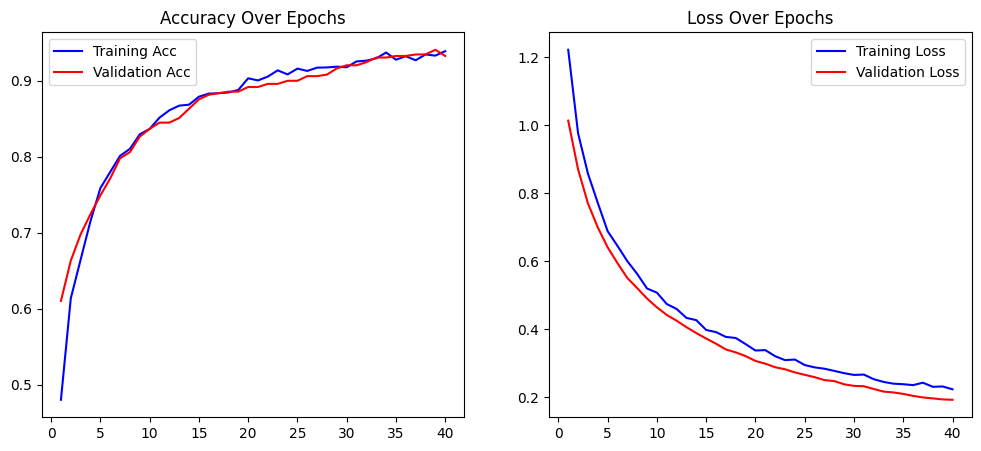

In [ ]:
plot_training_history(history_effnet)

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step


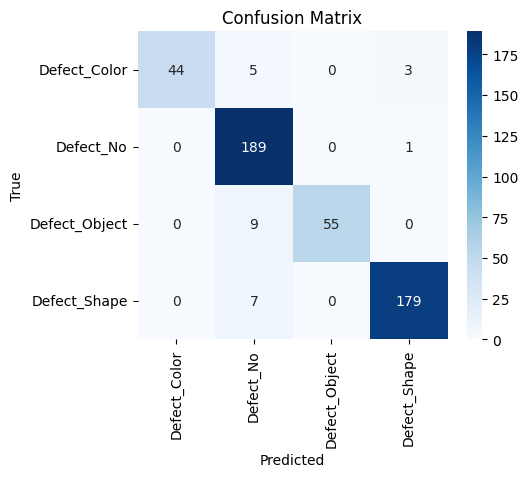


Classification Report:
               precision    recall  f1-score   support

 Defect_Color       1.00      0.85      0.92        52
    Defect_No       0.90      0.99      0.94       190
Defect_Object       1.00      0.86      0.92        64
 Defect_Shape       0.98      0.96      0.97       186

     accuracy                           0.95       492
    macro avg       0.97      0.92      0.94       492
 weighted avg       0.95      0.95      0.95       492



In [ ]:
evaluate_model(effnet_model, test_ds, class_names)

Total misclassified images: 25


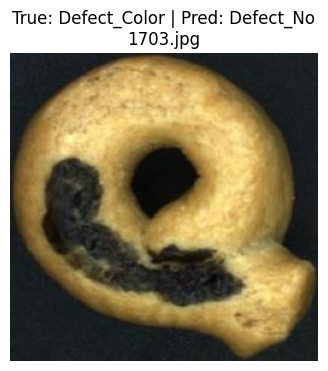

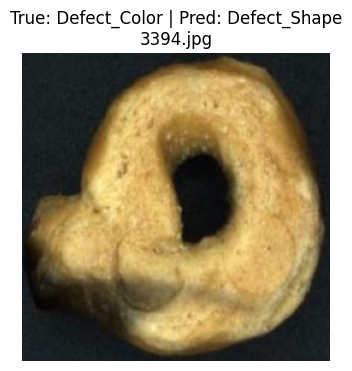

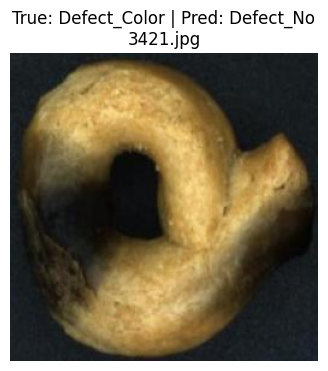

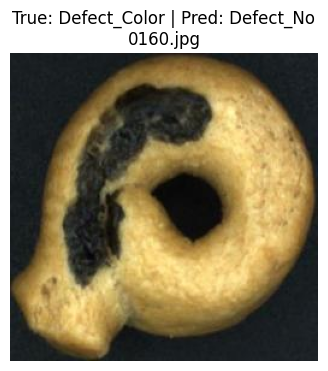

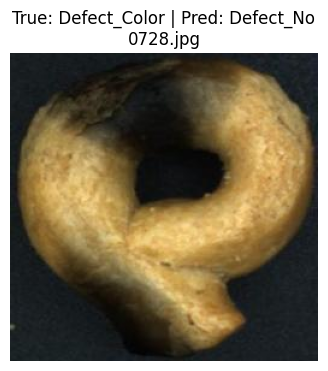

...

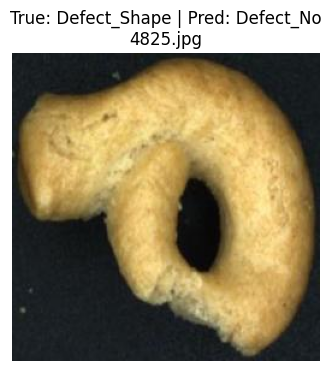

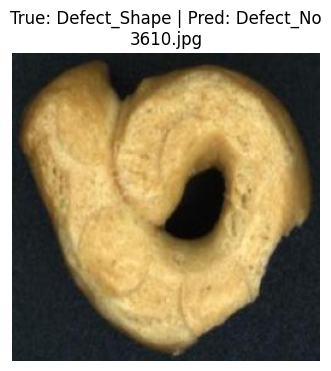

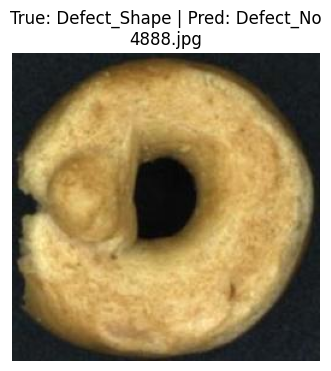

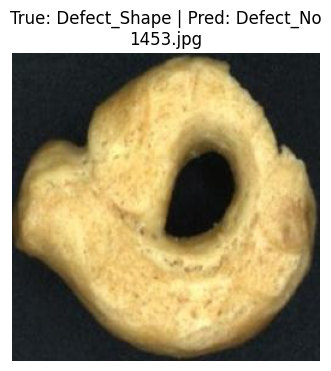

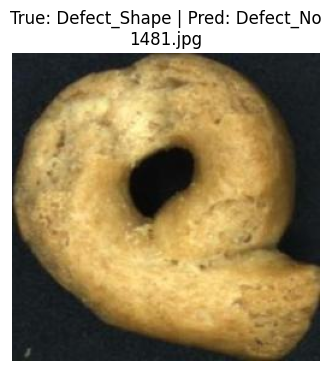

[{'file': '/content/drive/Shareddrives/CV_Project/Supervised_Classification/data/IndustryBiscuit/DS_multiclass/test/Defect_Color/1703.jpg',
  'true': 'Defect_Color',
  'pred': 'Defect_No',
  'img': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=256x256>},
 {'file': '/content/drive/Shareddrives/CV_Project/Supervised_Classification/data/IndustryBiscuit/DS_multiclass/test/Defect_Color/3394.jpg',
  'true': 'Defect_Color',
  'pred': 'Defect_Shape',
  'img': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=256x256>},
 {'file': '/content/drive/Shareddrives/CV_Project/Supervised_Classification/data/IndustryBiscuit/DS_multiclass/test/Defect_Color/3421.jpg',
  'true': 'Defect_Color',
  'pred': 'Defect_No',
  'img': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=256x256>},
 {'file': '/content/drive/Shareddrives/CV_Project/Supervised_Classification/data/IndustryBiscuit/DS_multiclass/test/Defect_Color/0160.jpg',
  'true': 'Defect_Color',
  'pred': 'Defect_No',
  'img': <PIL.Jp

In [ ]:
find_misclassified_from_dir(effnet_model, test_root, class_names, max_show=50)

In [ ]:
base_model = effnet_model.layers[2]
base_model.trainable = True
for layer in base_model.layers[:-40]:
    layer.trainable = False

effnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history_effnet_ft = effnet_model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=20,
    callbacks=[early_stop]
)

Epoch 1/20
123/123 ━━━━━━━━━━━━━━━━━━━━ 37s 170ms/step - accuracy: 0.7771 - loss: 0.6852 - val_accuracy: 0.9755 - val_loss: 0.1317
Epoch 2/20
123/123 ━━━━━━━━━━━━━━━━━━━━ 18s 142ms/step - accuracy: 0.9212 - loss: 0.3255 - val_accuracy: 0.9714 - val_loss: 0.1177
Epoch 3/20
123/123 ━━━━━━━━━━━━━━━━━━━━ 18s 143ms/step - accuracy: 0.9501 - loss: 0.2134 - val_accuracy: 0.9694 - val_loss: 0.1063
Epoch 4/20
123/123 ━━━━━━━━━━━━━━━━━━━━ 19s 156ms/step - accuracy: 0.9477 - loss: 0.1950 - val_accuracy: 0.9714 - val_loss: 0.0986
Epoch 5/20
123/123 ━━━━━━━━━━━━━━━━━━━━ 17s 140ms/step - accuracy: 0.9545 - loss: 0.1677 - val_accuracy: 0.9714 - val_loss: 0.0895
Epoch 6/20
123/123 ━━━━━━━━━━━━━━━━━━━━ 18s 144ms/step - accuracy: 0.9659 - loss: 0.1505 - val_accuracy: 0.9735 - val_loss: 0.0838
Epoch 7/20
123/123 ━━━━━━━━━━━━━━━━━━━━ 17s 141ms/step - accuracy: 0.9634 - loss: 0.1384 - val_accuracy: 0.9776 - val_loss: 0.0738
Epoch 8/20
123/123 ━━━━━━━━━━━━━━━━━━━━ 17s 138ms/step - accuracy: 0.9648 - loss: 0

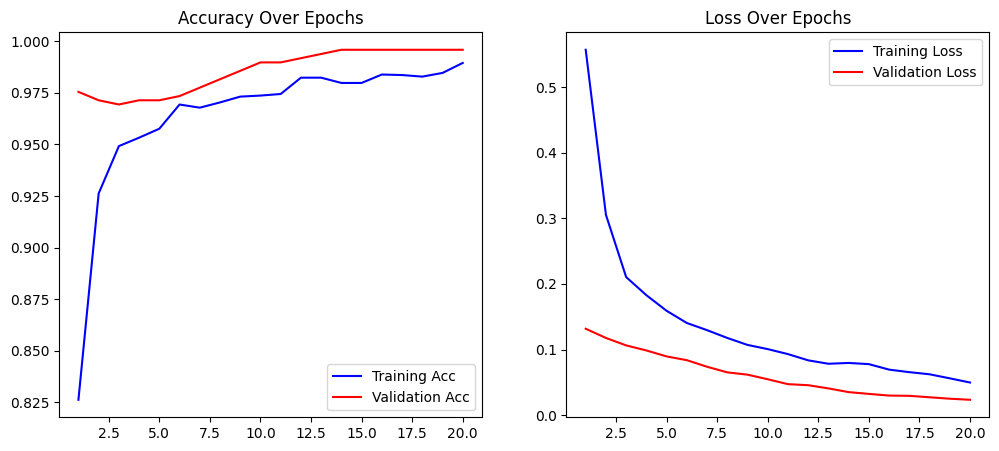

In [ ]:
plot_training_history(history_effnet_ft)

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 192ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


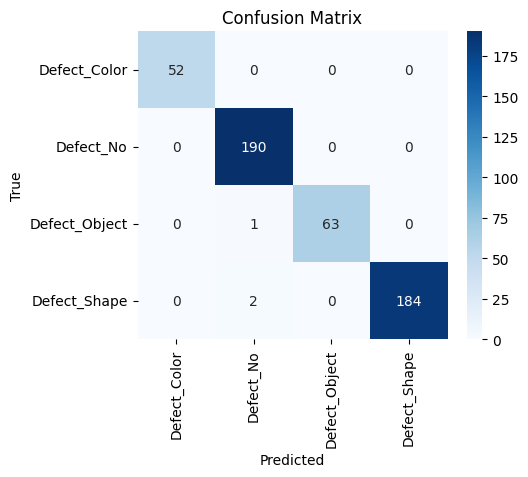


Classification Report:
               precision    recall  f1-score   support

 Defect_Color       1.00      1.00      1.00        52
    Defect_No       0.98      1.00      0.99       190
Defect_Object       1.00      0.98      0.99        64
 Defect_Shape       1.00      0.99      0.99       186

     accuracy                           0.99       492
    macro avg       1.00      0.99      0.99       492
 weighted avg       0.99      0.99      0.99       492



In [ ]:
evaluate_model(effnet_model, test_ds, class_names)

Total misclassified images: 3


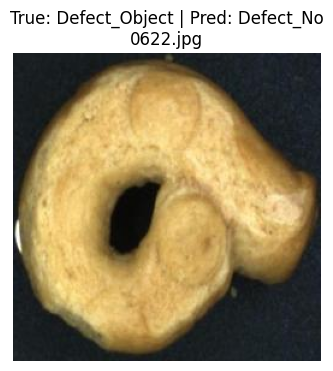

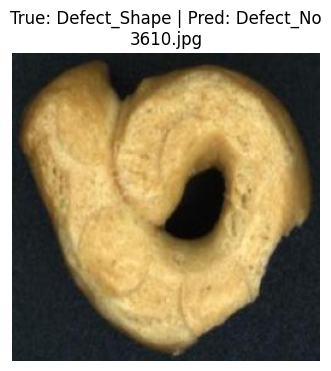

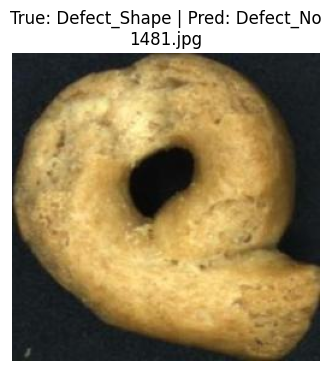

[{'file': '/content/drive/Shareddrives/CV_Project/Supervised_Classification/data/IndustryBiscuit/DS_multiclass/test/Defect_Object/0622.jpg',
  'true': 'Defect_Object',
  'pred': 'Defect_No',
  'img': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=256x256>},
 {'file': '/content/drive/Shareddrives/CV_Project/Supervised_Classification/data/IndustryBiscuit/DS_multiclass/test/Defect_Shape/3610.jpg',
  'true': 'Defect_Shape',
  'pred': 'Defect_No',
  'img': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=256x256>},
 {'file': '/content/drive/Shareddrives/CV_Project/Supervised_Classification/data/IndustryBiscuit/DS_multiclass/test/Defect_Shape/1481.jpg',
  'true': 'Defect_Shape',
  'pred': 'Defect_No',
  'img': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=256x256>}]

In [ ]:
find_misclassified_from_dir(effnet_model, test_root, class_names, max_show=50)

#### MobileNetV3 Large

In [ ]:
from tensorflow.keras.applications import MobileNetV3Large
from tensorflow.keras import layers, models
import tensorflow as tf

def build_mobilenetv3_large():
    base_model = MobileNetV3Large(
        weights='imagenet',
        include_top=False,
        input_shape=(256, 256, 3),
        pooling=None
    )

    base_model.trainable = False   # freeze backbone

    inputs = layers.Input(shape=(256, 256, 3))
    x = data_augmentation(inputs)
    x = layers.Rescaling(1./255)(x)

    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)

    outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)
    model = models.Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-4),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

mobilenet_model = build_mobilenetv3_large()
mobilenet_model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/applications/mobilenet_v3.py:517: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(


Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_14 (InputLayer)     │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_2 (Sequential)       │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_9 (Rescaling)         │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MobileNetV3Large (Functional)   │ (None, 8, 8, 960)      │     2,996,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 960)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 960)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │         3,844 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,000,196 (11.44 MB)

 Trainable params: 3,844 (15.02 KB)

 Non-trainable params: 2,996,352 (11.43 MB)

In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history_mobilenet = mobilenet_model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=30,
    callbacks=[early_stop]
)

Epoch 1/30
123/123 ━━━━━━━━━━━━━━━━━━━━ 25s 151ms/step - accuracy: 0.2708 - loss: 1.4138 - val_accuracy: 0.3878 - val_loss: 1.2504
Epoch 2/30
123/123 ━━━━━━━━━━━━━━━━━━━━ 16s 128ms/step - accuracy: 0.3581 - loss: 1.3293 - val_accuracy: 0.3837 - val_loss: 1.2344
Epoch 3/30
123/123 ━━━━━━━━━━━━━━━━━━━━ 17s 140ms/step - accuracy: 0.3823 - loss: 1.2837 - val_accuracy: 0.3898 - val_loss: 1.2315
Epoch 4/30
123/123 ━━━━━━━━━━━━━━━━━━━━ 17s 135ms/step - accuracy: 0.3627 - loss: 1.2945 - val_accuracy: 0.4388 - val_loss: 1.2296
Epoch 5/30
123/123 ━━━━━━━━━━━━━━━━━━━━ 17s 134ms/step - accuracy: 0.3584 - loss: 1.2896 - val_accuracy: 0.4184 - val_loss: 1.2279
Epoch 6/30
123/123 ━━━━━━━━━━━━━━━━━━━━ 16s 127ms/step - accuracy: 0.3611 - loss: 1.2760 - val_accuracy: 0.4980 - val_loss: 1.2262
Epoch 7/30
123/123 ━━━━━━━━━━━━━━━━━━━━ 16s 129ms/step - accuracy: 0.3943 - loss: 1.2628 - val_accuracy: 0.5204 - val_loss: 1.2245
Epoch 8/30
123/123 ━━━━━━━━━━━━━━━━━━━━ 16s 131ms/step - accuracy: 0.3814 - loss: 1

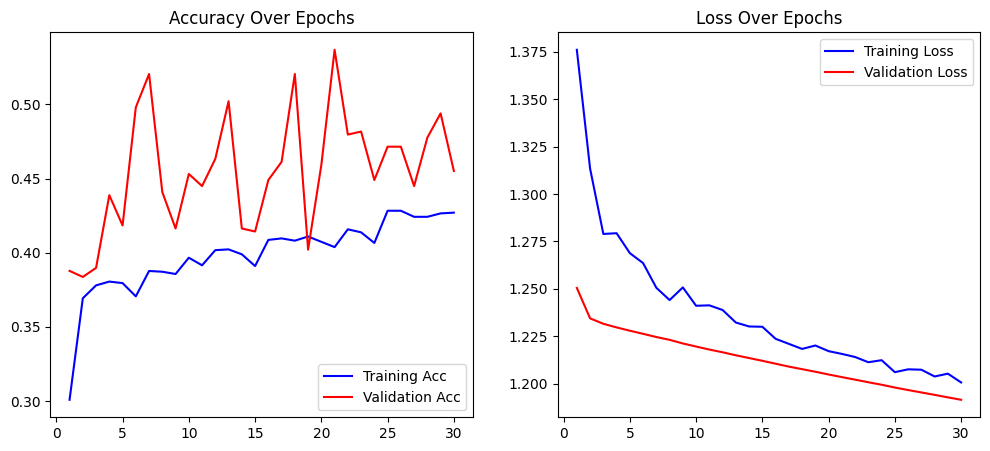

In [ ]:
plot_training_history(history_mobilenet)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


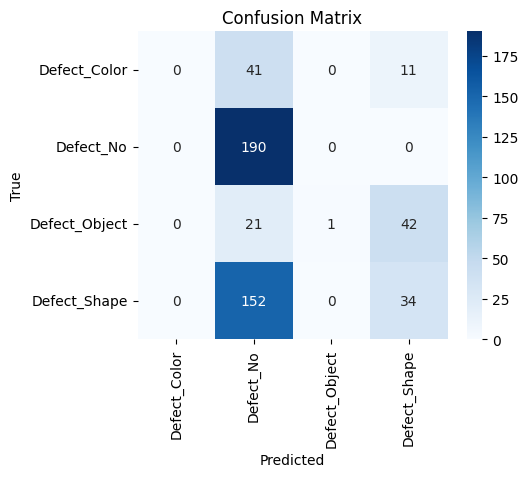


Classification Report:
               precision    recall  f1-score   support

 Defect_Color       0.00      0.00      0.00        52
    Defect_No       0.47      1.00      0.64       190
Defect_Object       1.00      0.02      0.03        64
 Defect_Shape       0.39      0.18      0.25       186

     accuracy                           0.46       492
    macro avg       0.47      0.30      0.23       492
 weighted avg       0.46      0.46      0.35       492



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
evaluate_model(mobilenet_model, test_ds, class_names)

In [ ]:
backbone = mobilenet_model.layers[3]
print(len(backbone.layers))

187


In [ ]:
fine_tune_at = len(backbone.layers) - 40

for layer in backbone.layers:
    layer.trainable = False

for layer in backbone.layers[fine_tune_at:]:
    layer.trainable = True

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)


In [ ]:
early_stop_ft = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history_ft = mobilenet_model.fit(
    train_ds,
    epochs=25,
    validation_data=valid_ds,
    callbacks=[early_stop_ft]
)


Epoch 1/25
123/123 ━━━━━━━━━━━━━━━━━━━━ 17s 134ms/step - accuracy: 0.4526 - loss: 1.1575 - val_accuracy: 0.4816 - val_loss: 1.1891
Epoch 2/25
123/123 ━━━━━━━━━━━━━━━━━━━━ 17s 135ms/step - accuracy: 0.5521 - loss: 1.0062 - val_accuracy: 0.4163 - val_loss: 1.2073
Epoch 3/25
123/123 ━━━━━━━━━━━━━━━━━━━━ 17s 142ms/step - accuracy: 0.5991 - loss: 0.9250 - val_accuracy: 0.3816 - val_loss: 1.3043
Epoch 4/25
123/123 ━━━━━━━━━━━━━━━━━━━━ 17s 134ms/step - accuracy: 0.6567 - loss: 0.8432 - val_accuracy: 0.1286 - val_loss: 1.5871
Epoch 5/25
123/123 ━━━━━━━━━━━━━━━━━━━━ 17s 134ms/step - accuracy: 0.6914 - loss: 0.7771 - val_accuracy: 0.1286 - val_loss: 2.1552
Epoch 6/25
123/123 ━━━━━━━━━━━━━━━━━━━━ 17s 136ms/step - accuracy: 0.7282 - loss: 0.7063 - val_accuracy: 0.1286 - val_loss: 2.8896


In [ ]:
resnet_model.save("/content/drive/Shareddrives/CV_Project/Supervised_Classification/resnet_final.keras")
effnet_model.save("/content/drive/Shareddrives/CV_Project/Supervised_Classification/efficientnet_final.keras")
mobilenet_model.save("/content/drive/Shareddrives/CV_Project/Supervised_Classification/mobilenet_final.keras")

# ===== Save only weights =====
resnet_model.save_weights("/content/drive/Shareddrives/CV_Project/Supervised_Classification/resnet_final.weights.h5")
effnet_model.save_weights("/content/drive/Shareddrives/CV_Project/Supervised_Classification/efficientnet_final.weights.h5")
mobilenet_model.save_weights("/content/drive/Shareddrives/CV_Project/Supervised_Classification/mobilenet_final.weights.h5")
